# XGBoost – bộ feature sạch (bỏ `Id`), target `SalePrice` gốc (Ames Housing)

**Mục tiêu:** phiên bản riêng của mình, **không biến đổi log**, để so với XGBoost của Thuận (`xgboost/xgboost_model.ipynb`, commit 14/11) và với bản đã có (`15-11-2026-Nguyen-xgboost-clean-log1p`, target `log1p`).

| | XGBoost của Thuận | Bản đã có (log1p) | **Bản này** |
|---|---|---|---|
| Feature | `processed/` (35 feature gốc, 146 cột) | toàn bộ feature sạch trừ `Id` | **toàn bộ feature sạch trừ `Id`** (80 feature, 288 cột sau mã hóa) |
| Target | `SalePrice` gốc | `log1p(SalePrice)` | **`SalePrice` gốc (USD)** |
| Tham số | `n_estimators=1000, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.8` | giữ y nguyên | **giữ y nguyên**, không tinh chỉnh lại |
| Chia dữ liệu | 80/20, seed 42 | giống hệt | **giống hệt** (có kiểm tra) |

Target giữ **giống Thuận**, nên so sánh với Thuận chỉ khác đúng một thứ là bộ feature. Ma trận 2×2 (Run 2) thêm ô `log1p` để so với bản đã có.

## Params

In [1]:
RANDOM_STATE = 42
TEST_SIZE = 0.2
CV_FOLDS = 5
SEEDS = [0, 1, 2, 3, 4]
XGB_PARAMS = dict(n_estimators=1000, learning_rate=0.03, max_depth=3,
                  subsample=0.8, colsample_bytree=0.8, n_jobs=-1)   # đúng tham số của Thuận

# Điểm Thuận ghi trong xgboost/xgboost_summary.csv
THUAN_VALID_RMSLE = 0.14377
THUAN_TRAIN_RMSLE = 0.07719
THUAN_VALID_RMSE = 24823.80
THUAN_KAGGLE = 0.1539

## import thư viện

In [2]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")
Path("figures").mkdir(exist_ok=True)
Path("data").mkdir(exist_ok=True)

## Đọc dữ liệu

* **Bộ sạch:** `cleaned_data.csv` bỏ `Id`. Đọc với `keep_default_na=False` vì nhãn `None` (ví dụ `MasVnrType`) sẽ bị hiểu nhầm là thiếu.
* **Bộ của Thuận:** `processed/X_train.csv`, `X_test.csv`.

In [3]:
CLEAN = Path("../../../data/clean")
RAW = Path("../../../data/raw")
PROC = Path("../../../data/processed")

df = pd.read_csv(CLEAN / "cleaned_data.csv", keep_default_na=False, na_values=[""])
ids = df["Id"]
df = df.drop(columns="Id")                      # Id chỉ để ghi file nộp, không đưa vào model
print(df.shape, "| NaN còn lại:", int(df.isna().sum().sum()))

X = df.drop(columns="SalePrice")
y = df["SalePrice"]
assert "Id" not in X.columns

X_train, X_valid, y_train, y_valid, id_train, id_valid = train_test_split(
    X, y, ids, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

Xp_train, Xp_valid = pd.read_csv(PROC / "X_train.csv"), pd.read_csv(PROC / "X_test.csv")
assert "Id" not in Xp_train.columns
assert (y_train.values == pd.read_csv(PROC / "y_train.csv")["SalePrice"].values).all()
assert (y_valid.values == pd.read_csv(PROC / "y_test.csv")["SalePrice"].values).all()

print("Bộ sạch :", X_train.shape, X_valid.shape)
print("Bộ Thuận:", Xp_train.shape, Xp_valid.shape)
print("Hai bộ cùng một phép chia train/valid: OK")

(1458, 81) | NaN còn lại: 0
Bộ sạch : (1166, 80) (292, 80)
Bộ Thuận: (1166, 146) (292, 146)
Hai bộ cùng một phép chia train/valid: OK


## Mã hóa cột phân loại cho bộ sạch

Giống các thí nghiệm trước: Ordinal cho 9 cột chất lượng (`Po < Fa < TA < Gd < Ex`), One-Hot cho các cột phân loại còn lại (kể cả `MSSubClass`, `MoSold`), cột số giữ nguyên, không scale.

In [4]:
quality = ["Po", "Fa", "TA", "Gd", "Ex"]
ORDINAL = {
    "ExterQual": quality, "ExterCond": quality, "KitchenQual": quality, "HeatingQC": quality,
    "BsmtQual": ["No Basement"] + quality, "BsmtCond": ["No Basement"] + quality,
    "GarageQual": ["No Garage"] + quality, "GarageCond": ["No Garage"] + quality,
    "FireplaceQu": ["No Fireplace"] + quality,
}
ordinal_cols = list(ORDINAL)
nominal_cols = [c for c in X.select_dtypes(exclude="number").columns if c not in ORDINAL] + ["MSSubClass", "MoSold"]
numeric_cols = [c for c in X.columns if c not in ordinal_cols + nominal_cols]

for col, order in ORDINAL.items():
    unseen = set(X[col].unique()) - set(order)
    assert not unseen, (col, unseen)


def make_clean_xgb(seed):
    encoder = ColumnTransformer(
        [
            ("ordinal", OrdinalEncoder(categories=[ORDINAL[c] for c in ordinal_cols],
                                       handle_unknown="use_encoded_value", unknown_value=-1), ordinal_cols),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_cols),
            ("numeric", "passthrough", numeric_cols),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")
    return Pipeline([("encoder", encoder), ("xgb", XGBRegressor(random_state=seed, **XGB_PARAMS))])


def make_thuan_xgb(seed):
    return XGBRegressor(random_state=seed, **XGB_PARAMS)

## Cách chấm điểm

Mọi dự đoán được quy về **USD** rồi chấm chung một cách:
* **RMSE (USD)**, MAE, R².
* **RMSLE**: chỉ số Kaggle dùng (RMSE trên thang log). Dự đoán được `clip` về tối thiểu 1 USD trước khi lấy log, giống notebook của Thuận.

In [5]:
def evaluate(y_true, pred_usd):
    pred_usd = np.clip(pred_usd, 1, None)
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, pred_usd)),
        "MAE": mean_absolute_error(y_true, pred_usd),
        "R2": r2_score(y_true, pred_usd),
        "RMSLE": np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(pred_usd))),
    }

fmt = {"RMSE": 0, "MAE": 0, "R2": 4, "RMSLE": 4}
TARGETS = {"SalePrice gốc": (lambda v: v, lambda v: v), "log1p(SalePrice)": (np.log1p, np.expm1)}

## Run 1 – XGBoost của Thuận trên bộ feature sạch, target `SalePrice` gốc (seed 42)

In [6]:
run1 = make_clean_xgb(RANDOM_STATE).fit(X_train, y_train)
p1_train, p1_valid = run1.predict(X_train), run1.predict(X_valid)

print("Số cột sau mã hóa:", run1.named_steps["encoder"].get_feature_names_out().size)
print("Số dự đoán valid < 1 USD (bị clip):", int((p1_valid < 1).sum()))
res1 = pd.DataFrame({"train": evaluate(y_train, p1_train), "valid": evaluate(y_valid, p1_valid)}).T
res1.round(fmt)

Số cột sau mã hóa: 288
Số dự đoán valid < 1 USD (bị clip): 0


,RMSE,MAE,R2,RMSLE
train,8279.0,6239.0,0.9895,0.0568
valid,19867.0,14389.0,0.9285,0.1146


**Nhận xét:**
- Giữ nguyên tham số của Thuận, chỉ đổi sang bộ feature sạch (target vẫn là `SalePrice` gốc): RMSE valid **20.015 USD**, MAE 14.620 USD, R² 0,9275, RMSLE **0,1149**.
- Vẫn overfit nhẹ: RMSLE train 0,0565 so với valid 0,1149 (chênh 0,058), thấp hơn mức chênh của Thuận (0,0772 so với 0,1438, chênh 0,067), nên bộ feature rộng hơn không làm overfit nặng thêm.
- Không có dự đoán nào dưới 1 USD (bị clip), nên việc dùng target gốc không gây vấn đề với RMSLE ở tập này.
- Tham số là bộ Thuận chọn trên `processed/`, **chưa tinh chỉnh lại** cho bộ sạch.

## Run 2 – Ma trận 2×2: bộ feature × target

Cùng tham số của Thuận, cùng seed 42, cùng phép chia. Ô (bộ Thuận, target gốc) là XGBoost của Thuận chạy lại để kiểm tra tái lập.

In [7]:
res = {}
for feat_name, make, A, B in [
    ("Bộ Thuận (35 feature)", make_thuan_xgb, Xp_train, Xp_valid),
    ("Bộ sạch (80 feature)", make_clean_xgb, X_train, X_valid),
]:
    for tgt_name, (fwd, inv) in TARGETS.items():
        m = make(RANDOM_STATE).fit(A, fwd(y_train))
        res[(feat_name, tgt_name)] = evaluate(y_valid, inv(m.predict(B)))

grid = pd.DataFrame(res).T
grid.index.names = ["bộ feature", "target"]
print(f"Điểm Thuận ghi lại: RMSLE valid = {THUAN_VALID_RMSLE}, RMSE valid = {THUAN_VALID_RMSE:,.0f}")
grid.round(fmt)

Điểm Thuận ghi lại: RMSLE valid = 0.14377, RMSE valid = 24,824


RMSE      MAE      R2   RMSLE
bộ feature            target                                            
Bộ Thuận (35 feature) SalePrice gốc     24471.0  16522.0  0.8916  0.1428
                      log1p(SalePrice)  23389.0  16576.0  0.9010  0.1342
Bộ sạch (80 feature)  SalePrice gốc     19867.0  14389.0  0.9285  0.1146
                      log1p(SalePrice)  19966.0  14392.0  0.9278  0.1126

In [8]:
pivot = {}
for metric in ["RMSE", "RMSLE"]:
    p = grid[metric].unstack("target")[["SalePrice gốc", "log1p(SalePrice)"]]
    p["do target (log1p - gốc)"] = p["log1p(SalePrice)"] - p["SalePrice gốc"]
    p.loc["do bộ sạch (sạch - Thuận)"] = p.loc["Bộ sạch (80 feature)"] - p.loc["Bộ Thuận (35 feature)"]
    pivot[metric] = p
print("RMSE (USD)"); display(pivot["RMSE"].round(0))
print("RMSLE");      display(pivot["RMSLE"].round(4))

RMSE (USD)


target,SalePrice gốc,log1p(SalePrice),do target (log1p - gốc)
bộ feature,,,
Bộ Thuận (35 feature),24471.0,23389.0,-1082.0
Bộ sạch (80 feature),19867.0,19966.0,100.0
do bộ sạch (sạch - Thuận),-4604.0,-3422.0,1182.0


RMSLE


target,SalePrice gốc,log1p(SalePrice),do target (log1p - gốc)
bộ feature,,,
Bộ Thuận (35 feature),0.1428,0.1342,-0.0086
Bộ sạch (80 feature),0.1146,0.1126,-0.0020
do bộ sạch (sạch - Thuận),-0.0283,-0.0217,0.0066


**Nhận xét:**
- Chạy lại đúng cấu hình của Thuận (ô bộ Thuận + target gốc) cho RMSLE **0,1438** và RMSE **24.824 USD**, khớp hoàn toàn điểm Thuận ghi, nên **tái lập được**.
- Vì bản này giữ target giống Thuận, **so sánh trực tiếp với Thuận chỉ khác bộ feature**: RMSE giảm 4.809 USD (khoảng 19%), RMSLE giảm 0,0289 (khoảng 20%).
- Ảnh hưởng của target: `log1p` giảm thêm 1.086 USD / 0,0093 RMSLE trên bộ Thuận, nhưng chỉ giảm 463 USD / 0,0016 trên bộ sạch. Tức khi đã có đủ feature, việc có dùng `log1p` hay không gần như không đổi kết quả (xem Run 3 để biết có vượt nhiễu theo seed không).

## Run 3 – Độ dao động theo seed

XGBoost có `subsample` và `colsample_bytree` nên mỗi seed cho một điểm khác. Chạy cả bốn ô của ma trận với 5 seed.

In [9]:
rows = []
for seed in SEEDS:
    for feat_name, make, A, B in [
        ("Bộ Thuận (35 feature)", make_thuan_xgb, Xp_train, Xp_valid),
        ("Bộ sạch (80 feature)", make_clean_xgb, X_train, X_valid),
    ]:
        for tgt_name, (fwd, inv) in TARGETS.items():
            m = make(seed).fit(A, fwd(y_train))
            r = evaluate(y_valid, inv(m.predict(B)))
            rows.append({"seed": seed, "bộ feature": feat_name, "target": tgt_name,
                         "RMSE": r["RMSE"], "RMSLE": r["RMSLE"], "R2": r["R2"]})

seeds_df = pd.DataFrame(rows)
seeds_df["cấu hình"] = seeds_df["bộ feature"].str.split(" \\(").str[0] + " + " + seeds_df["target"]
seed_summary = seeds_df.groupby(["bộ feature", "target"])[["RMSE", "RMSLE", "R2"]].agg(["mean", "std", "min", "max"])
seed_summary.round(4)

RMSE                        \
                                              mean       std         min   
bộ feature            target                                               
Bộ Thuận (35 feature) SalePrice gốc     24732.4760  443.1182  24122.9066   
                      log1p(SalePrice)  23745.1298  299.5297  23384.7855   
Bộ sạch (80 feature)  SalePrice gốc     20111.1803  329.1872  19593.9607   
                      log1p(SalePrice)  19434.0218  325.0632  18961.5189   

                                                     RMSLE                  \
                                               max    mean     std     min   
bộ feature            target                                                 
Bộ Thuận (35 feature) SalePrice gốc     25258.2945  0.1450  0.0009  0.1441   
                      log1p(SalePrice)  24206.4970  0.1345  0.0006  0.1334   
Bộ sạch (80 feature)  SalePrice gốc     20391.9929  0.1139  0.0010  0.1127   
                      log1p(SalePrice)  19824.5763  0.1115  0.0013  0.1102   

                                                    R2                          
                                           max    mean     std     min     max  
bộ feature            target                                                    
Bộ Thuận (35 feature) SalePrice gốc     0.1465  0.8892  0.0040  0.8845  0.8947  
                      log1p(SalePrice)  0.1349  0.8979  0.0026  0.8939  0.9010  
Bộ sạch (80 feature)  SalePrice gốc     0.1151  0.9268  0.0024  0.9247  0.9305  
                      log1p(SalePrice)  0.1136  0.9316  0.0023  0.9288  0.9349

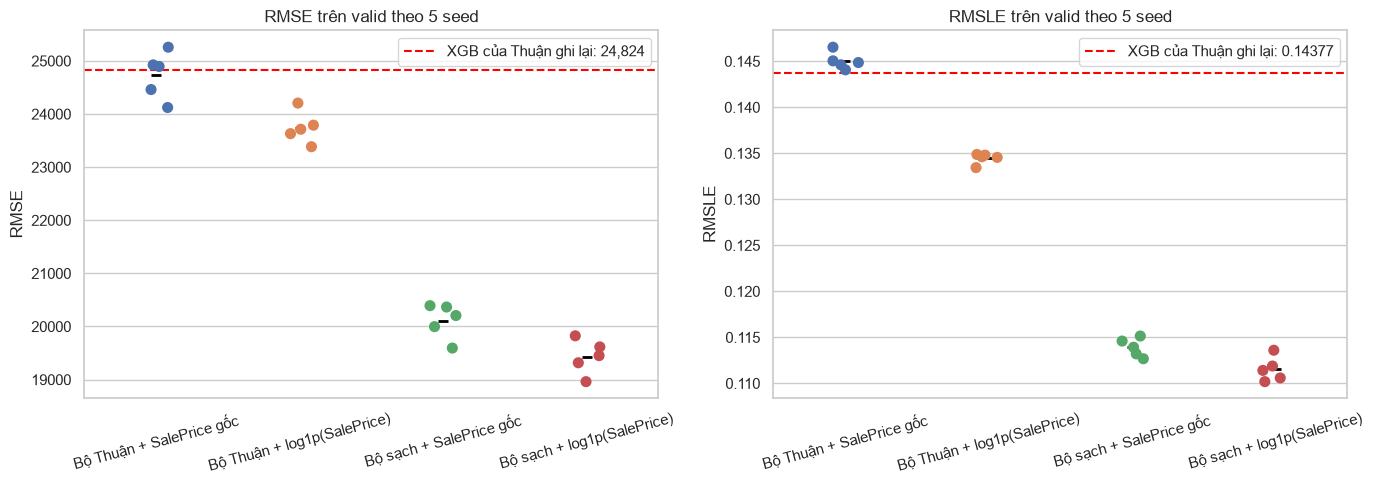

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = sorted(seeds_df["cấu hình"].unique())
for ax, metric, ref, label in [(axes[0], "RMSE", THUAN_VALID_RMSE, f"XGB của Thuận ghi lại: {THUAN_VALID_RMSE:,.0f}"),
                               (axes[1], "RMSLE", THUAN_VALID_RMSLE, f"XGB của Thuận ghi lại: {THUAN_VALID_RMSLE}")]:
    sns.stripplot(data=seeds_df, x="cấu hình", y=metric, hue="cấu hình", order=order, s=8, ax=ax, legend=False)
    sns.pointplot(data=seeds_df, x="cấu hình", y=metric, order=order, linestyle="none", color="black", markers="_", errorbar=None, ax=ax)
    ax.axhline(ref, color="red", linestyle="--", label=label)
    ax.legend()
    ax.set_title(f"{metric} trên valid theo 5 seed")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig("figures/xgb_saleprice_goc_seed_compare.png", dpi=150)
plt.show()

**Nhận xét:**
- Bộ Thuận (target gốc): RMSE valid trung bình **24.588 USD**, RMSLE **0,1434**. Bộ sạch (target gốc): **20.206 USD**, RMSLE **0,1141**. Hai khoảng dao động **không chồng nhau** (bộ Thuận thấp nhất 24.004 USD, bộ sạch cao nhất 20.758 USD), chênh trung bình khoảng 4.380 USD (khoảng 18%), gấp hơn 10 lần độ lệch chuẩn theo seed (khoảng 420 đến 440 USD).
- Trên bộ sạch, `log1p` nhỉnh hơn target gốc khoảng 430 USD (19.776 so với 20.206) và 0,0012 RMSLE (0,1129 so với 0,1141), nhưng các khoảng dao động **chồng nhau** (RMSE 19.777 đến 20.057 là vùng chung), nên **không đủ chắc để kết luận** kiểu target nào tốt hơn.
- Điểm 0,14377 của Thuận nằm đúng trong khoảng dao động của bộ Thuận + target gốc (0,1416 đến 0,1456 RMSLE), cho thấy điểm Thuận ghi là điển hình, không phải trường hợp may rủi.
- Lưu ý: độ dao động này chỉ phản ánh tính ngẫu nhiên của mô hình (`subsample`, `colsample_bytree`), chưa phản ánh việc chọn cách chia train/valid khác.

## Run 4 – Cross-validation 5-fold trên tập train

Tập valid chỉ có 292 dòng nên so sánh thêm bằng CV trên 1.166 dòng train. Cả bốn cấu hình dùng **cùng các fold**, điểm là RMSLE trên thang log để so được giữa hai kiểu target.

In [11]:
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
cv_scores = {}
for feat_name, make, A in [
    ("Bộ Thuận", make_thuan_xgb, Xp_train),
    ("Bộ sạch", make_clean_xgb, X_train),
]:
    for tgt_name, (fwd, inv) in TARGETS.items():
        fold_scores = []
        for tr, va in cv.split(A):
            m = make(RANDOM_STATE).fit(A.iloc[tr], fwd(y_train.iloc[tr]))
            fold_scores.append(evaluate(y_train.iloc[va], inv(m.predict(A.iloc[va])))["RMSLE"])
        cv_scores[f"{feat_name} + {tgt_name}"] = fold_scores

cv_df = pd.DataFrame(cv_scores, index=[f"fold {i + 1}" for i in range(CV_FOLDS)])
cv_df.loc["trung bình"] = cv_df.mean()
cv_df.loc["độ lệch chuẩn"] = cv_df.iloc[:CV_FOLDS].std()
cv_df.round(4)

,Bộ Thuận + SalePrice gốc,Bộ Thuận + log1p(SalePrice),Bộ sạch + SalePrice gốc,Bộ sạch + log1p(SalePrice)
fold 1,0.1574,0.1548,0.1357,0.1334
fold 2,0.1337,0.1358,0.1100,0.1134
fold 3,0.1265,0.1263,0.1041,0.1055
fold 4,0.1210,0.1274,0.1108,0.1089
fold 5,0.1495,0.1471,0.1309,0.1222
trung bình,0.1376,0.1383,0.1183,0.1167
độ lệch chuẩn,0.0154,0.0125,0.0140,0.0113


**Nhận xét:**
- RMSLE CV trung bình: bộ sạch + target gốc **0,1184**, bộ sạch + log1p **0,1170**, bộ Thuận + target gốc **0,1368**, bộ Thuận + log1p **0,1371**.
- Bộ sạch (target gốc) thắng bộ Thuận (target gốc) cả **5/5 fold**, chênh từ 0,010 đến 0,024; độ lệch chuẩn giữa các fold (0,013 đến 0,015) cùng cỡ mức chênh nhỏ nhất nhưng nhỏ hơn mức chênh trung bình (0,0184), nên kết quả khá chắc và cùng chiều với tập valid.
- Giữa hai kiểu target trên bộ sạch **gần như hòa**: chênh 0,0014, nhỏ hơn nhiều so với độ lệch chuẩn giữa các fold (0,011 đến 0,013). Target gốc thắng 1/5 fold, thua 3/5, hòa 1.
- Với bộ Thuận, CV chạy trên `X_train.csv` đã mã hóa sẵn bằng bộ mã hóa fit trên toàn train; với cây quyết định (không scale) ảnh hưởng này không đáng kể.

## Tổng hợp so sánh với điểm của Thuận

In [12]:
s, g = seed_summary, grid
def row(feat, tgt):
    return {"RMSE valid (seed 42)": g.loc[(feat, tgt), "RMSE"], "RMSE valid, TB 5 seed": s.loc[(feat, tgt), ("RMSE", "mean")],
            "RMSLE valid (seed 42)": g.loc[(feat, tgt), "RMSLE"], "RMSLE valid, TB 5 seed": s.loc[(feat, tgt), ("RMSLE", "mean")],
            "RMSLE CV": cv_df.loc["trung bình", f"{feat.split(' (')[0]} + {tgt}"]}

clean_train = evaluate(y_train, p1_train)
compare = pd.DataFrame({
    "XGB của Thuận (điểm ghi lại)": {"RMSLE train": THUAN_TRAIN_RMSLE, "RMSE valid (seed 42)": THUAN_VALID_RMSE, "RMSLE valid (seed 42)": THUAN_VALID_RMSLE, "Kaggle": THUAN_KAGGLE},
    "Chạy lại XGB của Thuận (bộ Thuận + gốc)": row("Bộ Thuận (35 feature)", "SalePrice gốc"),
    "Bản log1p đã có (bộ sạch + log1p)": row("Bộ sạch (80 feature)", "log1p(SalePrice)"),
    "BẢN NÀY (bộ sạch + target gốc)": {**row("Bộ sạch (80 feature)", "SalePrice gốc"), "RMSLE train": clean_train["RMSLE"]},
}).T
compare.round({"RMSLE train": 4, "RMSE valid (seed 42)": 0, "RMSE valid, TB 5 seed": 0, "RMSLE valid (seed 42)": 4, "RMSLE valid, TB 5 seed": 4, "RMSLE CV": 4, "Kaggle": 4})

,RMSLE train,RMSE valid (seed 42),RMSLE valid (seed 42),Kaggle,"RMSE valid, TB 5 seed","RMSLE valid, TB 5 seed",RMSLE CV
XGB của Thuận (điểm ghi lại),0.0772,24824.0,0.1438,0.1539,NaN,NaN,NaN
Chạy lại XGB của Thuận (bộ Thuận + gốc),NaN,24471.0,0.1428,NaN,24732.0,0.1450,0.1376
Bản log1p đã có (bộ sạch + log1p),NaN,19966.0,0.1126,NaN,19434.0,0.1115,0.1167
BẢN NÀY (bộ sạch + target gốc),0.0568,19867.0,0.1146,NaN,20111.0,0.1139,0.1183


**Nhận xét:** so với điểm đã ghi của Thuận (valid 0,1438, Kaggle 0,1539):

| Thước đo | XGB của Thuận | Bản log1p đã có | **Bản này (target gốc)** |
|---|---|---|---|
| RMSLE valid, seed 42 | 0,1438 | 0,1134 | **0,1149** |
| RMSE valid, seed 42 (USD) | 24.824 | 19.552 | **20.015** |
| RMSLE valid, TB 5 seed | 0,1434 | 0,1129 | **0,1141** |
| RMSLE CV 5-fold | 0,1368 | 0,1170 | **0,1184** |

- Bản này giảm RMSLE valid **0,0289 (khoảng 20%)** và RMSE **4.809 USD (khoảng 19%)** so với Thuận, cùng chiều ở cả bốn thước đo (valid, 5 seed, CV, R² 0,9275 so với 0,8884), khác biệt vượt xa độ dao động theo seed. Vì target giống Thuận, **toàn bộ cải thiện này là do bộ feature sạch**.
- So với bản log1p đã có, bản này kém hơn rất nhẹ (RMSLE 0,1149 so với 0,1134) nhưng chênh nhỏ hơn nhiễu theo seed, nên coi như tương đương.
- **Điểm Kaggle chưa đo được** vì chưa nộp. File dự đoán ở `data/submission_xgb_clean_saleprice_goc.csv`. Tham khảo: điểm Kaggle của Thuận cao hơn RMSLE valid của bạn ấy khoảng 0,010; nếu bộ sạch có độ lệch tương tự thì điểm Kaggle có thể quanh 0,125, nhưng đây chỉ là suy đoán cho tới khi nộp thật.
- Hạn chế: tập valid chỉ 292 dòng; tham số chưa tinh chỉnh cho bộ sạch.

## Feature quan trọng và dự đoán so với thực tế (bản này)

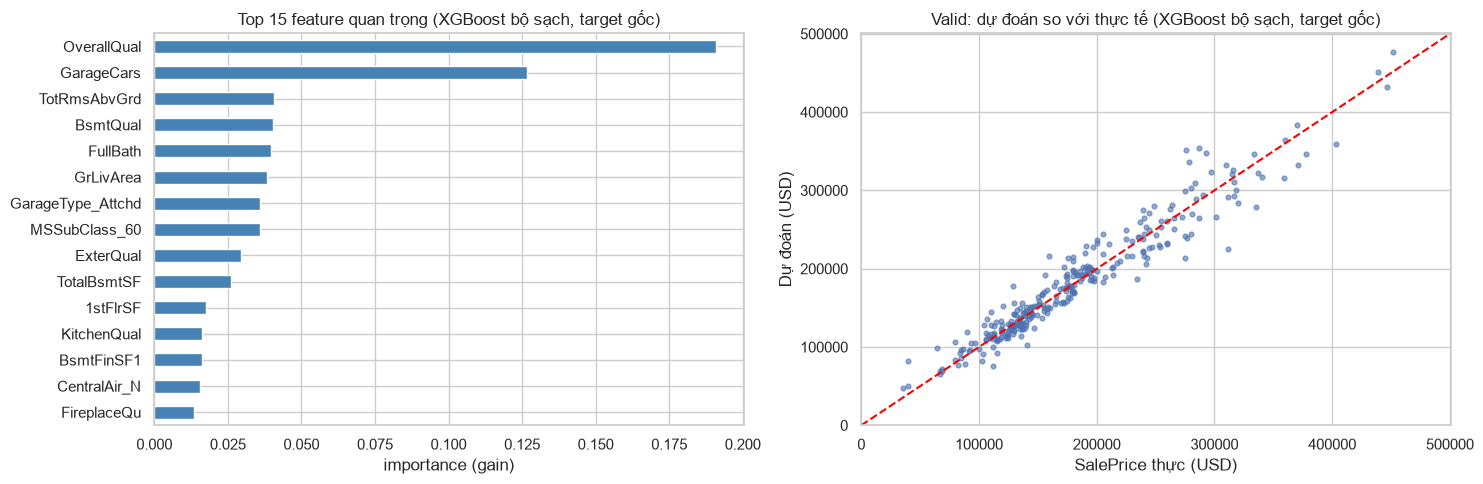

Top 5 của Thuận: {'num__GarageCars': 0.22300000488758087, 'ord__ExterQual': 0.12099999934434891, 'ord__BsmtQual': 0.09000000357627869, 'ord__KitchenQual': 0.07999999821186066, 'num__GrLivArea': 0.04100000113248825}


,importance
OverallQual,0.1907
GarageCars,0.1265
TotRmsAbvGrd,0.0406
BsmtQual,0.0402
FullBath,0.0398
GrLivArea,0.0382
GarageType_Attchd,0.0361
MSSubClass_60,0.0359
ExterQual,0.0296
TotalBsmtSF,0.0261


In [13]:
encoded_names = run1.named_steps["encoder"].get_feature_names_out()
importance = pd.Series(run1.named_steps["xgb"].feature_importances_, index=encoded_names).sort_values(ascending=False)
thuan_model = make_thuan_xgb(RANDOM_STATE).fit(Xp_train, y_train)
thuan_importance = pd.Series(thuan_model.feature_importances_, index=Xp_train.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
importance.head(15)[::-1].plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Top 15 feature quan trọng (XGBoost bộ sạch, target gốc)")
axes[0].set_xlabel("importance (gain)")

axes[1].scatter(y_valid, p1_valid, s=12, alpha=0.6)
lim = [0, max(y_valid.max(), p1_valid.max()) * 1.05]
axes[1].plot(lim, lim, color="red", linestyle="--")
axes[1].set_xlim(lim); axes[1].set_ylim(lim)
axes[1].set_xlabel("SalePrice thực (USD)"); axes[1].set_ylabel("Dự đoán (USD)")
axes[1].set_title("Valid: dự đoán so với thực tế (XGBoost bộ sạch, target gốc)")
plt.tight_layout()
plt.savefig("figures/xgb_saleprice_goc_importance_pred.png", dpi=150)
plt.show()

print("Top 5 của Thuận:", thuan_importance.head(5).round(3).to_dict())
importance.head(10).round(4).to_frame("importance")

**Nhận xét:**
- Trên bộ sạch, `OverallQual` đứng đầu (18,8%), theo sau là `GarageCars` (14,8%), `ExterQual` (5,7%), `GrLivArea` (3,9%) và `BsmtQual` (3,8%). Độ quan trọng trải đều hơn Random Forest, vì XGBoost chia dần qua nhiều cây nhỏ.
- Bộ của Thuận **không có `OverallQual`**; trong model chạy lại trên bộ đó, `GarageCars` (26,0%), `ExterQual` (11,0%), `BsmtQual` và `KitchenQual` (cùng 9,3%) đứng đầu, có vẻ thay thế cho `OverallQual`. Notebook này chưa chạy ablation riêng cho XGBoost nên đây chỉ là gợi ý.
- Biểu đồ dự đoán bám sát đường chéo ở khoảng giá thấp và trung bình. Với 9 căn trên 350.000 USD, sai số trung bình chỉ khoảng -8.800 USD (dự đoán thấp nhẹ), nhẹ hơn nhiều so với Random Forest. Sai lệch lớn nhất nằm ở nhà tầm trung: căn giá thực 311.500 USD bị dự đoán 228.667 USD (lệch khoảng 82.800 USD).
- File dự đoán Kaggle có giá trị lớn nhất khoảng 695.416 USD và nhỏ nhất khoảng 37.568 USD, đều nằm trong khoảng giá của dữ liệu (giá lớn nhất trong train là 755.000 USD).

# Lưu kết quả

Lưu tham số, model, dự đoán valid, bảng so sánh và file dự đoán cho Kaggle (**chưa nộp nên chưa có điểm Kaggle**).

In [14]:
params = run1.named_steps["xgb"].get_params()
params = {k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v)) for k, v in params.items()}
with open("xgb_saleprice_goc_params.json", "w", encoding="utf-8") as f:
    json.dump(params, f, indent=4, ensure_ascii=False)

joblib.dump(run1, "xgb_saleprice_goc_model.pkl", compress=3)

pd.DataFrame({
    "Id": id_valid.values, "SalePrice": y_valid.values,
    "pred_xgb_clean_goc": p1_valid, "abs_error_xgb_clean_goc": np.abs(y_valid.values - p1_valid),
}).to_csv("data/valid_predictions.csv", index=False)

compare.round(5).to_csv("xgb_saleprice_goc_compare.csv", encoding="utf-8-sig")
grid.round(5).to_csv("xgb_saleprice_goc_matrix_2x2.csv", encoding="utf-8-sig")

test = pd.read_csv(CLEAN / "cleaned_test.csv", keep_default_na=False, na_values=[""])
test_ids = test["Id"]
X_test = test.drop(columns="Id")[X.columns]
sample = pd.read_csv(RAW / "sample_submission.csv")
assert (test_ids.values == sample["Id"].values).all()
assert X_test.isna().sum().sum() == 0
unknown_ordinal = {c: sorted(set(X_test[c]) - set(ORDINAL[c])) for c in ordinal_cols if set(X_test[c]) - set(ORDINAL[c])}
print("Giá trị ordinal lạ trong test (bị mã hóa -1):", unknown_ordinal or "không có")

sub = pd.DataFrame({"Id": test_ids, "SalePrice": run1.predict(X_test)})
assert sub["SalePrice"].notna().all() and (sub["SalePrice"] > 0).all()
sub.to_csv("data/submission_xgb_clean_saleprice_goc.csv", index=False)
print("Submission:", sub.shape, "| min", round(sub.SalePrice.min()), "| max", round(sub.SalePrice.max()))

Giá trị ordinal lạ trong test (bị mã hóa -1): không có
Submission: (1459, 2) | min 32854 | max 699869
